## Onset speed (intermediate age = 3 wpf Danionella)

Speed onset for intermediate-age fish. Mixed phenotype: internal classification of continuous and intermittent swimming events

ROC analysis: test the predictive power of maximum onset speed on the bout outcome.

Figures are saved to the project `figures/` directory and to `onset_speed/media/`.

Import libraries:

In [2]:
import numpy as np
import matplotlib.pyplot as plt
def inline():
    %matplotlib inline
    plt.close('all')
def widget():
    %matplotlib widget
    plt.close('all')
import sys
from pathlib import Path
_code = Path.cwd() if (Path.cwd() / "paths.py").exists() else Path.cwd().parent
if str(_code.resolve()) not in [str(Path(p).resolve()) for p in sys.path]:
    sys.path.insert(0, str(_code.resolve()))
from paths import PROJECT_ROOT, DATA_DIR, FIGURES_DIR, notebook_media_dir
%load_ext autoreload
%autoreload 2
    
#from functions.visual_flow_behavior_plotting import *
from functions.visual_flow_behavior_analysis import *
#from functions.brain_analysis import *
from functions.utilities import *
#from functions.feedback_models import *
from functions.freely_swimming import *
from functions.MC_freely_swimming import *
from functions.MC_plots import *

import os
import h5py
from ipywidgets import interact,IntSlider
from scipy import fft
from scipy.ndimage import gaussian_filter
from skimage import io
import pickle
from scipy import fft
from sklearn.preprocessing import scale
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from scipy.stats import iqr
import pandas as pd
from scipy.interpolate import interp1d
import matplotlib.colors as mcolors
import matplotlib.cm as cm

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
print(os.getcwd()) 

<repo>/code/onset_speed


In [4]:
# Paths from code/paths.py (project root, data, figures, local media)
path = str(PROJECT_ROOT)
path_data = str(DATA_DIR)
path_figures = str(FIGURES_DIR)
path_media = str(notebook_media_dir("onset_speed"))
print(path, path_data, path_figures)

<repo> <repo>/data <repo>/figures


In [5]:
from functions.MC_utilities import *
[color_y, color_m, color_o, color_low_boutID, color_med_boutID, color_high_boutID, color_cont, color_bout] = get_colors()
group_colors = [color_y, color_m, color_o]

#### Import data:

In [6]:
#fish_ids_young=['13_06May24_1','13_30Oct24_3','13_30Oct24_4','14_27Mar24_1','14_31Oct24_1']
fish_ids_young=['13_06May24_1','13_30Oct24_3','13_30Oct24_4','14_31Oct24_1']
index_y = list(range(0, len(fish_ids_young)))
print(index_y)

[0, 1, 2, 3]


In [7]:
fish_ids_intermediate=['17_21May24_2','18_22May24_1','18_22May24_2','19_23May24_5','20_05Jun24_1','20_05Jun24_2','20_12Jun24_1','21_06Dec24_1','21_06Dec24_2','21_06Jun24_1','25_10Jun24_1']
index_i = list( range(len(fish_ids_young), len(fish_ids_young)+len(fish_ids_intermediate)) )
print(index_i)

[4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]


In [8]:
#fish_ids_old=['26_02May24_2','27_12Jun24_1','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']
fish_ids_old=['26_02May24_2','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']
index_o = list( range( len(fish_ids_young)+len(fish_ids_intermediate) , len(fish_ids_young)+len(fish_ids_intermediate)+len(fish_ids_old) ) )
print(index_o)

[15, 16, 17, 18, 19]


In [9]:
fish_ids=fish_ids_young+fish_ids_intermediate+fish_ids_old
len(fish_ids)

20

In [10]:
fish_ids

['13_06May24_1',
 '13_30Oct24_3',
 '13_30Oct24_4',
 '14_31Oct24_1',
 '17_21May24_2',
 '18_22May24_1',
 '18_22May24_2',
 '19_23May24_5',
 '20_05Jun24_1',
 '20_05Jun24_2',
 '20_12Jun24_1',
 '21_06Dec24_1',
 '21_06Dec24_2',
 '21_06Jun24_1',
 '25_10Jun24_1',
 '26_02May24_2',
 '28_04May24_1',
 '30_06May24_2',
 '34_11Dec24_1',
 '34_11Dec24_3']

In [11]:
index_groups = {
    '1-2 wpf': index_y,
    '3 wpf': index_i,
    '4-5 wpf': index_o
}

In [12]:
age_list = [int(fid.split('_')[0]) for fid in fish_ids]
print(age_list)

[13, 13, 13, 14, 17, 18, 18, 19, 20, 20, 20, 21, 21, 21, 25, 26, 28, 30, 34, 34]


In [13]:
#SORTING BY ETA
index_cont = [0, 1, 2, 8]
index_mix = [3, 4, 5, 6, 7, 9, 11, 12, 13, 14, 17]
index_bout = [10, 15, 16, 18, 19]

Load:

In [14]:
speed_clean = pd.read_hdf(os.path.join(path_data, f"speed_clean.h5"), key='df')

In [15]:
speed_clean

,ID,t_c,vfish_c,vtail_c,dangletail_c,angletail_c,freqtail_c,mean_thrust_c
0,13_06May24_1,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
1,13_06May24_1,0.003333,NaN,NaN,NaN,NaN,NaN,NaN
2,13_06May24_1,0.006667,NaN,NaN,NaN,NaN,NaN,NaN
3,13_06May24_1,0.010000,NaN,NaN,NaN,NaN,NaN,NaN
4,13_06May24_1,0.013333,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
21727813,34_11Dec24_3,320.736667,NaN,NaN,NaN,NaN,NaN,NaN
21727814,34_11Dec24_3,320.740000,NaN,NaN,NaN,NaN,NaN,NaN
21727815,34_11Dec24_3,320.743333,NaN,NaN,NaN,NaN,NaN,NaN
21727816,34_11Dec24_3,320.746667,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
thrust_thresholds = pd.read_hdf(os.path.join(path_data, f"thrust_thresholds.h5"), key='df')

In [17]:
thrust_thresholds

,ID,thrust_thr,mask_movetail
0,13_06May24_1,0.000331,False
1,13_06May24_1,0.000331,False
2,13_06May24_1,0.000331,False
3,13_06May24_1,0.000331,False
4,13_06May24_1,0.000331,False
...,...,...,...
21727813,34_11Dec24_3,0.025991,False
21727814,34_11Dec24_3,0.025991,False
21727815,34_11Dec24_3,0.025991,False
21727816,34_11Dec24_3,0.025991,False


In [18]:
onsets = pd.read_hdf(os.path.join(path_data, f"onsets.h5"), key='df')

In [19]:
onsets

,ID,onset_indices,initial_vfish,initial_vtail,bout_duration
0,13_06May24_1,1369,6.717492,102.127655,2.566667
1,13_06May24_1,2987,4.772649,90.986139,1.966667
2,13_06May24_1,4877,7.283671,136.008985,1.780000
3,13_06May24_1,5695,6.163918,100.164392,2.900000
4,13_06May24_1,6601,3.750249,69.222574,0.966667
...,...,...,...,...,...
45480,34_11Dec24_3,92811,24.794113,263.748909,0.213333
45481,34_11Dec24_3,92984,35.093076,348.691133,0.213333
45482,34_11Dec24_3,93206,38.267398,332.921438,0.196667
45483,34_11Dec24_3,93407,35.724430,275.439541,0.216667


In [20]:
t_c_list=[]
vtail_c_list=[]
vfish_c_list=[]
mean_thrust_c_list=[]
angletail_c_list=[]
dangletail_c_list=[]
freqtail_c_list=[]

for fish_ID in tqdm(fish_ids):
    speed_clean_fish=subset_by_fish(fish_ID,DF1=speed_clean)[0]
    t_c_list.append(speed_clean_fish['t_c'].values)
    vfish_c_list.append(speed_clean_fish['vfish_c'].values)
    vtail_c_list.append(speed_clean_fish['vtail_c'].values)    
    mean_thrust_c_list.append(speed_clean_fish['mean_thrust_c'].values)
    angletail_c_list.append(speed_clean_fish['angletail_c'].values)
    dangletail_c_list.append(speed_clean_fish['dangletail_c'].values)
    freqtail_c_list.append(speed_clean_fish['freqtail_c'].values)

  0%|          | 0/20 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|▌         | 1/20 [00:03<00:59,  3.13s/it]

Subsetting data of the fish 13_30Oct24_3


 10%|█         | 2/20 [00:05<00:52,  2.91s/it]

...

 90%|█████████ | 18/20 [00:52<00:05,  2.91s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████▌| 19/20 [00:55<00:02,  2.88s/it]

Subsetting data of the fish 34_11Dec24_3


100%|██████████| 20/20 [00:57<00:00,  2.89s/it]


In [21]:
thrust_thr_list=[]
mask_movetail_list=[]

for fish_ID in tqdm(fish_ids):
    thrust_thresholds_fish=subset_by_fish(fish_ID,DF1=thrust_thresholds)[0]
    thrust_thr_list.append(thrust_thresholds_fish['thrust_thr'].values[0])
    mask_movetail_list.append(thrust_thresholds_fish['mask_movetail'].values)

  0%|          | 0/20 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|▌         | 1/20 [00:03<01:02,  3.28s/it]

Subsetting data of the fish 13_30Oct24_3


 10%|█         | 2/20 [00:07<01:03,  3.55s/it]

...

 90%|█████████ | 18/20 [00:54<00:05,  2.95s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████▌| 19/20 [00:57<00:02,  2.90s/it]

Subsetting data of the fish 34_11Dec24_3


100%|██████████| 20/20 [01:01<00:00,  3.06s/it]


In [22]:
onset_indices_list=[]
initial_vfish_list=[]
initial_vtail_list=[]
bout_duration_list=[]
onset_times_list=[]
i=0
for fish_ID in tqdm(fish_ids):
    print(i, fish_ID)
    onsets_fish=subset_by_fish(fish_ID,DF1=onsets)[0]
    onset_indices_list.append(onsets_fish['onset_indices'].values)
    initial_vfish_list.append(onsets_fish['initial_vfish'].values)
    initial_vtail_list.append(onsets_fish['initial_vtail'].values)
    bout_duration_list.append(onsets_fish['bout_duration'].values)
    i=i+1
    
for i in range(len(fish_ids)):  
    onset_times_list.append(t_c_list[i][onset_indices_list[i]])

100%|██████████| 20/20 [00:00<00:00, 149.78it/s]


0 13_06May24_1
Subsetting data of the fish 13_06May24_1
1 13_30Oct24_3
Subsetting data of the fish 13_30Oct24_3
2 13_30Oct24_4
Subsetting data of the fish 13_30Oct24_4
3 14_31Oct24_1
Subsetting data of the fish 14_31Oct24_1
4 17_21May24_2
Subsetting data of the fish 17_21May24_2
5 18_22May24_1
Subsetting data of the fish 18_22May24_1
6 18_22May24_2
Subsetting data of the fish 18_22May24_2
7 19_23May24_5
Subsetting data of the fish 19_23May24_5
8 20_05Jun24_1
Subsetting data of the fish 20_05Jun24_1
9 20_05Jun24_2
Subsetting data of the fish 20_05Jun24_2
10 20_12Jun24_1
Subsetting data of the fish 20_12Jun24_1
11 21_06Dec24_1
Subsetting data of the fish 21_06Dec24_1
12 21_06Dec24_2
Subsetting data of the fish 21_06Dec24_2
13 21_06Jun24_1
Subsetting data of the fish 21_06Jun24_1
14 25_10Jun24_1
Subsetting data of the fish 25_10Jun24_1
15 26_02May24_2
Subsetting data of the fish 26_02May24_2
16 28_04May24_1
Subsetting data of the fish 28_04May24_1
17 30_06May24_2
Subsetting data of the fi

## start some plots to visualize data

17_21May24_2


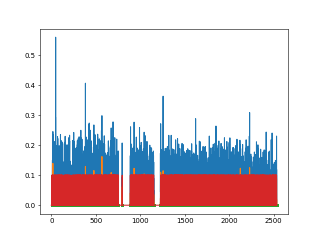

In [24]:
i=4

print(fish_ids[i])

dt=1/300
default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=50)
ax.plot(t_c_list[i],vtail_c_list[i]/1000,'-')
#ax.plot(t_c_list[i],dangletail_c_list[i]/10,'-')
ax.plot(t_c_list[i],mean_thrust_c_list[i],'-')
#ax.axhline(thrust_thr_list[i],c='k')
ax.plot(t_c_list[i][mask_movetail_list[i]], np.zeros(np.sum(mask_movetail_list[i])),'.')

ax.plot(t_c_list[i],mask_movetail_list[i]/10,'-')

#ax.set_xlim(255,255.5)
plt.show()

#### Onset traces 

In [25]:
color_bout = '#785ef0'
color_cont = '#648fff'
c_int = color_bout
c_cont = color_cont

In [26]:
i=10

In [27]:
dt=1/300
t_before=0.1
t_after=1
@interact(n=(0,len(onset_indices_list[i])-1,1))
def plot(n=0):
    default()
    widget()
    fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=50)
    ax.axhline(0,color='lightgray')
    ax.axvline(0,color='lightgray')
    t_onset=t_c_list[i][onset_indices_list[i][n]]
    indices=(t_c_list[i]>t_onset-t_before)&(t_c_list[i]<t_onset+t_after)
    ax.plot(t_c_list[i][indices]-t_onset,10*vfish_c_list[i][indices],'.-',alpha=0.6)
    ax.plot(t_c_list[i][indices]-t_onset,vtail_c_list[i][indices],'.-',alpha=0.6)
    ax.axvline(bout_duration_list[i][n],color='gray')
    ax.set_xlim(-t_before,t_after)

    plt.show()

interactive(children=(IntSlider(value=0, description='n', max=6182), Output()), _dom_classes=('widget-interact…

# intermediate regime

In [28]:
index_i = index_mix 

vfish_c_onsets_cont_tot = [[] for _ in range(len(index_i))]
vfish_c_onsets_int_tot = [[] for _ in range(len(index_i))]
vtail_c_onsets_cont_tot = [[] for _ in range(len(index_i))]
vtail_c_onsets_int_tot = [[] for _ in range(len(index_i))]

vfish_c_onsets_all_tot = [[] for _ in range(len(index_i))]
bout_duration_all_tot = [[] for _ in range(len(index_i))]

j = 0
dur_thr=0.8 # duration threshold for continuous bouts

for i in index_i:
    
    dt=1/300
    t_before=0.1
    t_after=1

    i_before=round(t_before/dt)
    i_after=round(t_after/dt)


    vfish_c_onsets=np.full((len(onset_indices_list[i]),i_before+i_after),np.nan)
    vtail_c_onsets=np.full((len(onset_indices_list[i]),i_before+i_after),np.nan)

    for n in range(len(onset_indices_list[i])):
        if onset_indices_list[i][n]-i_before<0 or onset_indices_list[i][n]+i_after>=len(vfish_c_list[i]):
            continue
        vfish_c_onsets[n]=np.copy(vfish_c_list[i][onset_indices_list[i][n]-i_before:onset_indices_list[i][n]+i_after])
        vtail_c_onsets[n]=np.copy(vtail_c_list[i][onset_indices_list[i][n]-i_before:onset_indices_list[i][n]+i_after])
        
        vfish_c_onsets[n,:i_before]=0
        vtail_c_onsets[n,:i_before]=0

        if bout_duration_list[i][n]<t_after:
            vfish_c_onsets[n,i_before+round(bout_duration_list[i][n]/dt):]=0
            vtail_c_onsets[n,i_before+round(bout_duration_list[i][n]/dt):]=0
            

    vfish_c_onsets_cont_tot[j] = vfish_c_onsets[np.array(bout_duration_list[i])>dur_thr]
    vtail_c_onsets_cont_tot[j] = vtail_c_onsets[np.array(bout_duration_list[i])>dur_thr]

    vfish_c_onsets_int_tot[j] = vfish_c_onsets[np.array(bout_duration_list[i])<dur_thr]
    vtail_c_onsets_int_tot[j] = vtail_c_onsets[np.array(bout_duration_list[i])<dur_thr]
    
    vfish_c_onsets_all_tot[j] = vfish_c_onsets[np.array(bout_duration_list[i])>0]
    bout_duration_all_tot[j] = bout_duration_list[i]

    j = j + 1


In [29]:
len(vfish_c_onsets_all_tot)

11

In [30]:
len(vfish_c_onsets_all_tot[0])

414

In [31]:
len(bout_duration_all_tot[0])

414

# one fish

In [32]:
i = 4

In [33]:
len(vtail_c_onsets_cont_tot)


11

In [34]:
vtail_c_onsets_int_tot[i].shape

(4425, 330)

## vfish - onset - one fish

In [35]:
vfish_c_onsets_cont = vfish_c_onsets_cont_tot[i] 
vfish_c_onsets_med_cont = np.nanquantile(vfish_c_onsets_cont,0.5,axis=0)
vfish_c_onsets_iqp_cont=np.nanquantile(vfish_c_onsets_cont,0.75,axis=0)-np.nanquantile(vfish_c_onsets_cont,0.5,axis=0)
vfish_c_onsets_iqm_cont=np.nanquantile(vfish_c_onsets_cont,0.5,axis=0)-np.nanquantile(vfish_c_onsets_cont,0.25,axis=0)
vfish_c_onsets_mean_cont = np.nanmean(vfish_c_onsets_cont, axis=0)
vfish_c_onsets_std_cont = np.nanmean(vfish_c_onsets_cont, axis=0)
    
vfish_c_onsets_int = vfish_c_onsets_int_tot[i] 
vfish_c_onsets_med_int = np.nanquantile(vfish_c_onsets_int,0.5,axis=0)
vfish_c_onsets_iqp_int=np.nanquantile(vfish_c_onsets_int,0.75,axis=0)-np.nanquantile(vfish_c_onsets_int,0.5,axis=0)
vfish_c_onsets_iqm_int=np.nanquantile(vfish_c_onsets_int,0.5,axis=0)-np.nanquantile(vfish_c_onsets_int,0.25,axis=0)
vfish_c_onsets_mean_int = np.nanmean(vfish_c_onsets_int, axis=0)
vfish_c_onsets_std_int = np.nanmean(vfish_c_onsets_int, axis=0)

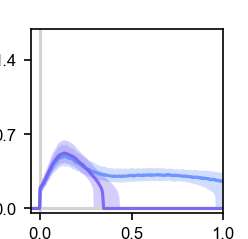

In [36]:
default()
widget()
arial()

cm_to_inch = 1 / 2.54
fig_width_cm = 4.2
fig_height_cm = 4.05

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch),   dpi=150)

plt.axhline(0,color='lightgray')
plt.axvline(0,color='lightgray')


plt.plot(dt*np.arange(-i_before,i_after),vfish_c_onsets_med_cont,c=c_cont,alpha=0.9)
plt.fill_between(dt*np.arange(-i_before,i_after),vfish_c_onsets_med_cont-vfish_c_onsets_iqm_cont,vfish_c_onsets_med_cont+vfish_c_onsets_iqp_cont,color=c_cont,alpha=0.3,ec=None)

plt.plot(dt*np.arange(-i_before,i_after),vfish_c_onsets_med_int,c=c_int,alpha=0.9)
plt.fill_between(dt*np.arange(-i_before,i_after),vfish_c_onsets_med_int-vfish_c_onsets_iqm_int,vfish_c_onsets_med_int+vfish_c_onsets_iqp_int,color=c_int,alpha=0.3,ec=None)

plt.xlim(-0.05,dur_thr)
plt.ylim(-0.4,17)

plt.xticks([0, 0.5, 1]) #s
plt.xlabel('time (s)')

plt.yticks([0, 7, 14], ['0.0', '0.7', '1.4']) #cm/s
plt.ylabel(r'$v (\mathrm{cm/s})$')

#plt.legend()

#fig.savefig(os.path.join(path_figures, "example_initial_speed_cont_int_one_fish.pdf"), format="pdf")

plt.show()

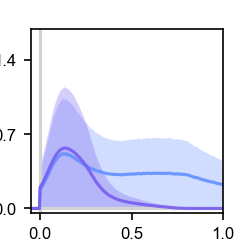

In [37]:
dt = 1/300

default()
widget()
arial()

cm_to_inch = 1 / 2.54
fig_width_cm = 4.2
fig_height_cm = 4.05

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch),   dpi=150)

plt.axhline(0,color='lightgray')
plt.axvline(0,color='lightgray')


plt.plot(dt*np.arange(-i_before,i_after),vfish_c_onsets_mean_cont,c=c_cont,alpha=0.9)
plt.fill_between(dt*np.arange(-i_before,i_after),vfish_c_onsets_mean_cont-vfish_c_onsets_std_cont,vfish_c_onsets_mean_cont+vfish_c_onsets_std_cont,color=c_cont,alpha=0.3,ec=None)

plt.plot(dt*np.arange(-i_before,i_after),vfish_c_onsets_mean_int,c=c_int,alpha=0.9)
plt.fill_between(dt*np.arange(-i_before,i_after),vfish_c_onsets_mean_int-vfish_c_onsets_std_int,vfish_c_onsets_mean_int+vfish_c_onsets_std_int,color=c_int,alpha=0.3,ec=None)

plt.xlim(-0.05,dur_thr)
plt.ylim(-0.4,17)

plt.xticks([0, 0.5, 1]) #s
plt.xlabel('time (s)')

plt.yticks([0, 7, 14], ['0.0', '0.7', '1.4']) #cm/s
plt.ylabel(r'$v (\mathrm{cm/s})$')

#plt.legend()

#fig.savefig(os.path.join(path_figures, "example_initial_speed_cont_int_one_fish.pdf"), format="pdf")

plt.show()

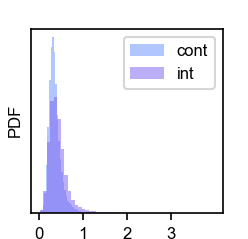

In [38]:
default()
widget()
arial()

cm_to_inch = 1 / 2.54
fig_width_cm = 4.2
fig_height_cm = 4.05

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch),   dpi=150)

plt.hist(vfish_c_onsets_cont[vfish_c_onsets_cont>0.1], density = 'True', bins=50, color=c_cont, alpha = 0.5, label = 'cont')
plt.hist(vfish_c_onsets_int[vfish_c_onsets_int>0.1], density = 'True', bins=50, color=c_int, alpha = 0.5, label = 'int')
plt.legend()
plt.yticks([])

plt.xticks([0, 10, 20, 30], ['0', '1', '2', '3']) #cm/s

plt.xlabel(r'$V_i\ (\mathrm{cm/s})$')
plt.ylabel('PDF')

#fig.savefig(os.path.join(path_figures, "initial_speed_cont_int_one_fish.pdf"), format="pdf")
plt.show()

# all fish: one by one

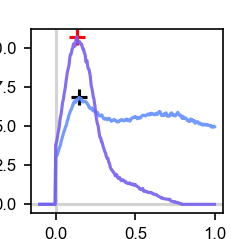

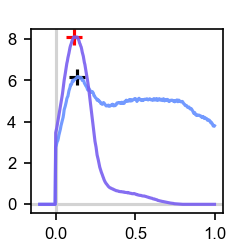

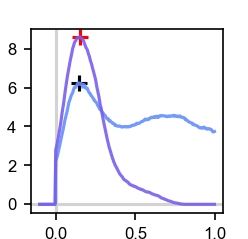

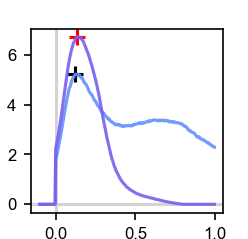

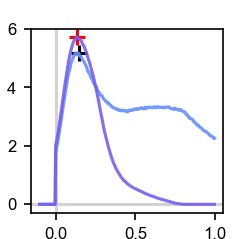

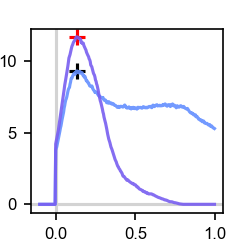

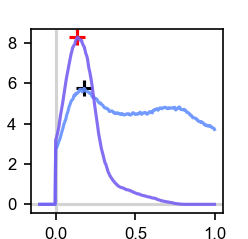

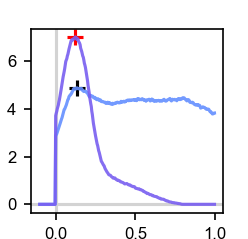

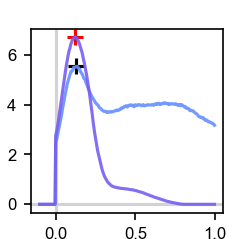

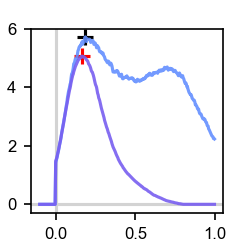

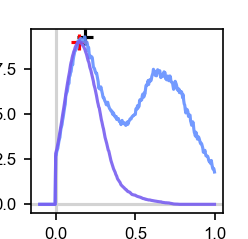

In [39]:
# Dictionary to store all statistics per fish
fish_stats = {}

for i in range(len(index_i)):
    fish_id = fish_ids[index_i[i]]  # assuming you have a list of fish_ids

    fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=150)
    time_onset = dt * np.arange(-i_before, i_after)

    # CONTINUOUS
    vfish_c_onsets_cont = vfish_c_onsets_cont_tot[i]
    med_cont = np.nanquantile(vfish_c_onsets_cont, 0.5, axis=0)
    iqp_cont = np.nanquantile(vfish_c_onsets_cont, 0.75, axis=0) - med_cont
    iqm_cont = med_cont - np.nanquantile(vfish_c_onsets_cont, 0.25, axis=0)
    mean_cont = np.nanmean(vfish_c_onsets_cont, axis=0)
    std_cont = np.nanstd(vfish_c_onsets_cont, axis=0)

    # INTERMITTENT
    vfish_c_onsets_int = vfish_c_onsets_int_tot[i]
    med_int = np.nanquantile(vfish_c_onsets_int, 0.5, axis=0)
    iqp_int = np.nanquantile(vfish_c_onsets_int, 0.75, axis=0) - med_int
    iqm_int = med_int - np.nanquantile(vfish_c_onsets_int, 0.25, axis=0)
    mean_int = np.nanmean(vfish_c_onsets_int, axis=0)
    std_int = np.nanstd(vfish_c_onsets_int, axis=0)

    # Max values
    vmax_cont = np.nanmax(mean_cont)
    tmax_cont = time_onset[np.nanargmax(mean_cont)]

    vmax_int = np.nanmax(mean_int)
    tmax_int = time_onset[np.nanargmax(mean_int)]

    # Plotting
    plt.axhline(0, color='lightgray')
    plt.axvline(0, color='lightgray')
    plt.plot(time_onset, mean_cont, c=c_cont, alpha=0.9)
    plt.plot(time_onset, mean_int, c=c_int, alpha=0.9)
    plt.scatter(tmax_cont, vmax_cont, color='black', marker='+', s=60)
    plt.scatter(tmax_int, vmax_int, color='red', marker='+', s=60)

    # Store statistics
    fish_stats[fish_id] = {
        'cont': {
            'time_onset': time_onset,
            'mean': mean_cont,
            'std': std_cont,
            'median': med_cont,
            'iqr_minus': iqm_cont,
            'iqr_plus': iqp_cont,
            'vmax': vmax_cont,
            'tmax': tmax_cont
        },
        'int': {
            'time_onset': time_onset,
            'mean': mean_int,
            'std': std_int,
            'median': med_int,
            'iqr_minus': iqm_int,
            'iqr_plus': iqp_int,
            'vmax': vmax_int,
            'tmax': tmax_int
        }
    }

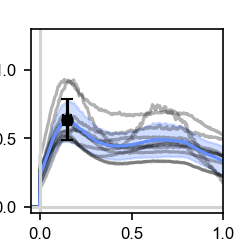

In [40]:
# Stack all 'cont' mean traces into an array
cont_means = np.stack([fish_stats[fish_ids[index_i[i]]]['cont']['mean'] for i in range(len(index_i))])
cont_vmaxs = np.stack([fish_stats[fish_ids[index_i[i]]]['cont']['vmax'] for i in range(len(index_i))])
cont_tmaxs = np.stack([fish_stats[fish_ids[index_i[i]]]['cont']['tmax'] for i in range(len(index_i))])

cont_mean_across_fish = np.nanmean(cont_means, axis=0)
cont_std_across_fish = np.nanstd(cont_means, axis=0)

cont_mean_vmax_across_fish = np.nanmean(cont_vmaxs, axis=0)
cont_std_vmax_across_fish = np.nanstd(cont_vmaxs, axis=0)

cont_mean_tmax_across_fish = np.nanmean(cont_tmaxs, axis=0)
cont_std_tmax_across_fish = np.nanstd(cont_tmaxs, axis=0)

default()
widget()
arial()

cm_to_inch = 1 / 2.54
fig_width_cm = 4.2
fig_height_cm = 4.05

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch),   dpi=150)

for i in range(len(index_i)):
    time_onset = dt * np.arange(-i_before, i_after)
    plt.plot(time_onset, fish_stats[fish_ids[index_i[i]]]['cont']['mean'], 'black', alpha = 0.3)
plt.plot(time_onset, cont_mean_across_fish, color=c_cont)
plt.fill_between(time_onset,cont_mean_across_fish-cont_std_across_fish,cont_mean_across_fish+cont_std_across_fish,color=c_cont,alpha=0.3)
plt.errorbar(cont_mean_tmax_across_fish, cont_mean_vmax_across_fish, 
             xerr=cont_std_tmax_across_fish, yerr=cont_std_vmax_across_fish, 
             fmt='o', color='black', markersize=5, capsize=3)

plt.axhline(0,color='lightgray')
plt.axvline(0,color='lightgray')
plt.xlim(-0.05,dur_thr)
plt.ylim(-0.4,13)

plt.xticks([0, 0.5, 1]) #s
plt.xlabel('time (s)')

plt.yticks([0, 5, 10], ['0.0', '0.5', '1.0']) #cm/s
plt.ylabel(r'$v_{f} (\mathrm{cm/s})$')

plt.show()

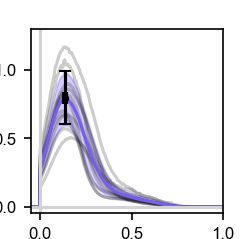

In [41]:
# Stack all 'int' mean traces into an array
int_means = np.stack([fish_stats[fish_ids[index_i[i]]]['int']['mean'] for i in range(len(index_i))])
int_vmaxs = np.stack([fish_stats[fish_ids[index_i[i]]]['int']['vmax'] for i in range(len(index_i))])
int_tmaxs = np.stack([fish_stats[fish_ids[index_i[i]]]['int']['tmax'] for i in range(len(index_i))])

# Compute mean and std across fish
int_mean_across_fish = np.nanmean(int_means, axis=0)
int_std_across_fish = np.nanstd(int_means, axis=0)

int_mean_vmax_across_fish = np.nanmean(int_vmaxs, axis=0)
int_std_vmax_across_fish = np.nanstd(int_vmaxs, axis=0)

int_mean_tmax_across_fish = np.nanmean(int_tmaxs, axis=0)
int_std_tmax_across_fish = np.nanstd(int_tmaxs, axis=0)

default()
widget()
arial()

cm_to_inch = 1 / 2.54
fig_width_cm = 4.2
fig_height_cm = 4.05

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch),   dpi=150)

for i in range(len(index_i)):
    time_onset = dt * np.arange(-i_before, i_after)
    plt.plot(time_onset, fish_stats[fish_ids[index_i[i]]]['int']['mean'], 'black', alpha=0.2)
plt.plot(time_onset, int_mean_across_fish, color=c_int)
plt.fill_between(time_onset, int_mean_across_fish - int_std_across_fish,
                 int_mean_across_fish + int_std_across_fish, color=c_int, alpha=0.3)
plt.errorbar(int_mean_tmax_across_fish, int_mean_vmax_across_fish,
             xerr=int_std_tmax_across_fish, yerr=int_std_vmax_across_fish,
             fmt='.', color='black', markersize=5, capsize=3)

plt.axhline(0,color='lightgray')
plt.axvline(0,color='lightgray')
plt.xlim(-0.05,dur_thr)
plt.ylim(-0.4,13)

plt.xticks([0, 0.5, 1]) #s
plt.xlabel('time (s)')

plt.yticks([0, 5, 10], ['0.0', '0.5', '1.0']) #cm/s
plt.ylabel(r'$v_{f} (\mathrm{cm/s})$')

plt.show()

0.1490909090909091 6.372227428281372
0.13575757575757577 7.96304335312752


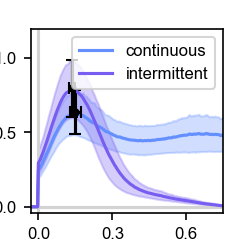

In [51]:
default()
widget()
arial()

cm_to_inch = 1 / 2.54
fig_width_cm = 4.2
fig_height_cm = 4.05

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch),   dpi=150)

plt.axhline(0,color='lightgray')
plt.axvline(0,color='lightgray')

plt.plot(time_onset, cont_mean_across_fish, color=c_cont, label ='continuous')
plt.fill_between(time_onset,cont_mean_across_fish-cont_std_across_fish,
                 cont_mean_across_fish+cont_std_across_fish,color=c_cont,alpha=0.3)
plt.errorbar(cont_mean_tmax_across_fish, cont_mean_vmax_across_fish, 
             xerr=cont_std_tmax_across_fish, yerr=cont_std_vmax_across_fish, 
             fmt='o', color='black', markersize=3, capsize=3)

plt.plot(time_onset, int_mean_across_fish, color=c_int, label ='intermittent')
plt.fill_between(time_onset, int_mean_across_fish - int_std_across_fish,
                 int_mean_across_fish + int_std_across_fish, color=c_int, alpha=0.3)
plt.errorbar(int_mean_tmax_across_fish, int_mean_vmax_across_fish,
             xerr=int_std_tmax_across_fish, yerr=int_std_vmax_across_fish,
             fmt='o', color='black', markersize=3, capsize=3)

plt.xlim(-0.03,0.75)
plt.ylim(-0.4,12)

plt.xticks([0, 0.3, 0.6]) #s
plt.xlabel('time (s)')

plt.yticks([0, 5, 10], ['0.0', '0.5', '1.0']) #cm/s
plt.ylabel(r'$v_{f} (\mathrm{cm/s})$')

plt.legend()
fig.savefig(os.path.join(path_figures, "Fig3b_onset_speed_cont_int_intermediate_fish.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig3b_onset_speed_cont_int_intermediate_fish.pdf"), format="pdf", bbox_inches='tight', dpi=200)

print(cont_mean_tmax_across_fish, cont_mean_vmax_across_fish)
print(int_mean_tmax_across_fish, int_mean_vmax_across_fish)
plt.show()

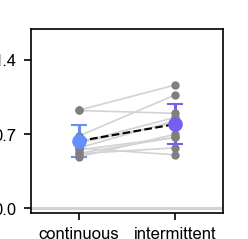

In [43]:
default()
widget()
arial()

cm_to_inch = 1 / 2.54
fig_width_cm = 4.2
fig_height_cm = 4.05

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=150)

# Plotting the means and standard deviations across fish
plt.axhline(0, color='lightgray')
plt.errorbar(0, cont_mean_vmax_across_fish, yerr=cont_std_vmax_across_fish, fmt='o', color=color_cont, capsize=4, label='mean ± std')
plt.errorbar(1, int_mean_vmax_across_fish, yerr=int_std_vmax_across_fish, fmt='o', color=color_bout, capsize=4, label='mean ± std')

# Plot individual points + lines
for cont, bout in zip(cont_vmaxs, int_vmaxs):
    plt.plot([0, 1], [cont, bout], '-', color='lightgray', linewidth=0.8)
plt.plot(np.zeros_like(cont_vmaxs), cont_vmaxs, '.', color='gray')
plt.plot(np.ones_like(int_vmaxs), int_vmaxs, '.', color='gray')

plt.plot([0, 1], [cont_mean_vmax_across_fish, int_mean_vmax_across_fish], '--', color='black', linewidth=1)


# Formatting
plt.xlim(-0.5, 1.5)
plt.ylim(-0.4,17)

plt.xticks([0, 1], ['continuous', 'intermittent'])
plt.yticks([0, 7, 14], ['0.0', '0.7', '1.4'])  # cm/s
plt.ylabel(r'$v_{max} (\mathrm{cm/s})$')
plt.xlabel(r'swimming')

fig.savefig(os.path.join(path_figures, "Fig_3c_max_speed_onset_intermediate_age.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_3c_max_speed_onset_intermediate_age.pdf"), format="pdf", bbox_inches='tight', dpi=200)

plt.show()

In [44]:
from scipy.stats import ttest_rel

# Paired t-test (assuming normality of differences)
t_stat, p_val = ttest_rel(cont_vmaxs, int_vmaxs)

print(f"P-value (paired t-test): {p_val:.3e}")
stars_from_p(p_val)

P-value (paired t-test): 2.553e-03


'**'

# Figure 3c: 
combine 'onset_speed_development' with 'onset_speed_intermediate_age'

In [48]:
mean_y, std_y = 5.041048341760499, 0.06547246410009752
mean_m, std_m = 0.13333333333333333, 7.405583027604644
mean_o, std_o = 18.85470149060185, 3.745039477509846

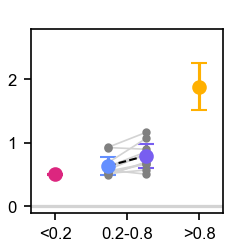

In [49]:
# --- Colors for groups ---
color_y = '#dc267f'
color_i = '#fe6100'
color_o = '#ffb000'

default()
widget()
arial()

cm_to_inch = 1 / 2.54
fig_width_cm = 4.2
fig_height_cm = 4.05

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=150)

# Plotting the means and standard deviations across fish
plt.axhline(0, color='lightgray')
ds = 0.1
plt.errorbar(0 + ds, cont_mean_vmax_across_fish, yerr=cont_std_vmax_across_fish, fmt='o', color=color_cont, capsize=4, label='mean ± std')
plt.errorbar(1 - ds, int_mean_vmax_across_fish, yerr=int_std_vmax_across_fish, fmt='o', color=color_bout, capsize=4, label='mean ± std')

plt.errorbar(-1, mean_y, yerr=std_y, fmt='o', color=color_y, capsize=4, label='mean ± std')
#plt.errorbar(0.5, mean_m, yerr=std_m, fmt='o', color=color_i, capsize=4, label='mean ± std')
plt.errorbar(2, mean_o, yerr=std_o, fmt='o', color=color_o, capsize=4, label='mean ± std')


# Plot individual points + lines
for cont, bout in zip(cont_vmaxs, int_vmaxs):
    plt.plot([0 + ds, 1 - ds], [cont, bout], '-', color='lightgray', linewidth=0.8)
plt.plot(np.zeros_like(cont_vmaxs) + ds, cont_vmaxs, '.', color='gray')
plt.plot(np.ones_like(int_vmaxs) - ds, int_vmaxs, '.', color='gray')

plt.plot([0 + ds, 1 - ds], [cont_mean_vmax_across_fish, int_mean_vmax_across_fish], '--', color='black', linewidth=1)

# --- Axis formatting ---
plt.axhline(0, color='lightgray')
plt.xlim(-1.5, 2.5)
plt.xticks([-1, 0.5, 2], ['<0.2', '0.2-0.8', '>0.8'])
plt.xlabel(r'\eta')
plt.ylim(-1,28)
plt.yticks([0, 10, 20], ['0', '1', '2'])
plt.ylabel(r'$v_{max}$ (cm/s)')

fig.savefig(os.path.join(path_figures, "Fig_3c_maximum_speed_stat_all_together.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_3c_maximum_speed_stat_all_together.pdf"), format="pdf", bbox_inches='tight', dpi=200)

plt.show()

# ROC curves

In [52]:
print(len(vfish_c_onsets_cont_tot))
cmap = plt.cm.tab20
colors = [cmap(i) for i in np.linspace(0, 0.9, 11)]

11


In [53]:
from scipy.ndimage import gaussian_filter1d
import numpy as np

vfish_c_onsets_tot_sorted = [[] for _ in range(len(vfish_c_onsets_cont_tot))]
Max_vfish_c_onsets_tot_sorted = [[] for _ in range(len(vfish_c_onsets_cont_tot))]
eta_tot_sorted = [[] for _ in range(len(vfish_c_onsets_cont_tot))]

for n in range(len(vfish_c_onsets_cont_tot)):
    time_onset = dt * np.arange(-i_before, i_after)
    zeros_cont = np.zeros(vfish_c_onsets_cont_tot[n].shape[0])
    ones_int = np.ones(vfish_c_onsets_int_tot[n].shape[0])
    
    # Concatenate values and labels
    vfish_all = np.concatenate([vfish_c_onsets_cont_tot[n], vfish_c_onsets_int_tot[n]])
    eta_all = np.concatenate([zeros_cont, ones_int])

    vfish_filtered = []
    max_vals = []
    eta_vals = []

    for i in range(eta_all.shape[0]):
        smoothed = gaussian_filter1d(vfish_all[i], sigma=10)
        max_idx = np.argmax(smoothed[:150])
        max_val = smoothed[max_idx]
        max_time = time_onset[max_idx]
        
        if max_time>0.150:
            vfish_filtered.append(vfish_all[i])
            max_vals.append(max_val)
            eta_vals.append(eta_all[i])
    
    vfish_c_onsets_tot_sorted[n] = vfish_filtered
    Max_vfish_c_onsets_tot_sorted[n] = max_vals
    eta_tot_sorted[n] = eta_vals

In [54]:
from sklearn.metrics import roc_curve, auc

fpr_list = [[] for i in range(len(vfish_c_onsets_cont_tot))]
tpr_list = [[] for i in range(len(vfish_c_onsets_cont_tot))]
auc_list = [[] for i in range(len(vfish_c_onsets_cont_tot))]

for n in range(len(vfish_c_onsets_cont_tot)):
    x = Max_vfish_c_onsets_tot_sorted[n]  # continuous scores or predictions
    y = eta_tot_sorted[n]  # binary labels (0 or 1)
    # Compute ROC curve and ROC area
    fpr, tpr, _ = roc_curve(y, x)
    roc_auc = auc(fpr, tpr)
    
    fpr_list[n] = fpr
    tpr_list[n] = tpr
    auc_list[n] = roc_auc


auc_mean 0.6415445568084922
auc_std 0.08670496166904676


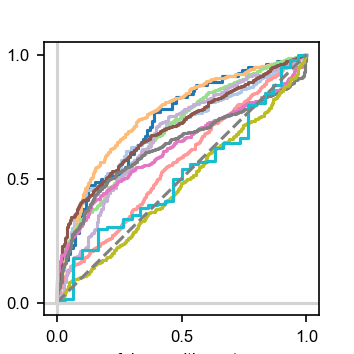

In [57]:
default()
widget()
arial()

cm_to_inch = 1 / 2.54
fig_width_cm = 6
fig_height_cm = 6

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch),   dpi=150)

for n in range(len(vfish_c_onsets_cont_tot)):
    plt.plot(fpr_list[n], tpr_list[n], '-',lw=1.5, color=colors[n], label=f'auc = {auc_list[n]:.2f}')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
#plt.title('receiver operating characteristic')
#plt.legend(loc="lower right")
plt.axhline(0,color='lightgray')
plt.axvline(0,color='lightgray')
plt.xticks([0,0.5,1])
plt.yticks([0,0.5,1])
#plt.grid(True)
print('auc_mean', np.mean(np.array(auc_list)))
print('auc_std', np.std(np.array(auc_list)))
fig.savefig(os.path.join(path_figures, "Fig_S8a_ROC_max_speed_cont_int_all_intermediate_fish.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_S8a_ROC_max_speed_cont_int_all_intermediate_fish.pdf"), format="pdf", bbox_inches='tight', dpi=200)
plt.show()

In [58]:
#null model: randomize the scores and labels independently

fpr_list_null = [[] for _ in range(len(vfish_c_onsets_cont_tot))]
tpr_list_null = [[] for _ in range(len(vfish_c_onsets_cont_tot))]
auc_list_null = [[] for _ in range(len(vfish_c_onsets_cont_tot))]

for n in range(len(vfish_c_onsets_cont_tot)):
    x = np.array(Max_vfish_c_onsets_tot_sorted[n])  # continuous scores
    y = np.array(eta_tot_sorted[n])                 # binary labels (0 or 1)
    
    # Randomize x and y independently to break any real relationship
    x_null = np.random.permutation(x)
    y_null = np.random.permutation(y)

    # Compute ROC curve and ROC AUC for null model
    fpr, tpr, _ = roc_curve(y_null, x_null)
    roc_auc = auc(fpr, tpr)

    fpr_list_null[n] = fpr
    tpr_list_null[n] = tpr
    auc_list_null[n] = roc_auc

In [59]:

#To statistically test whether the real AUCs (auc_list) are significantly higher than the null AUCs (auc_list_null), 
#you can use a Mann–Whitney U test (non-parametric, appropriate for comparing two independent distributions).
from scipy.stats import mannwhitneyu
auc_real = np.array(auc_list)
auc_null = np.array(auc_list_null)

stat, p_value = mannwhitneyu(auc_real, auc_null, alternative='greater')

print(f"Mann-Whitney U test: statistic = {stat:.3f}, p-value = {p_value:.5f}")
stars_from_p(p_val)

Mann-Whitney U test: statistic = 105.000, p-value = 0.00193


'**'

auc_mean 0.6415445568084922
auc_std 0.08670496166904676


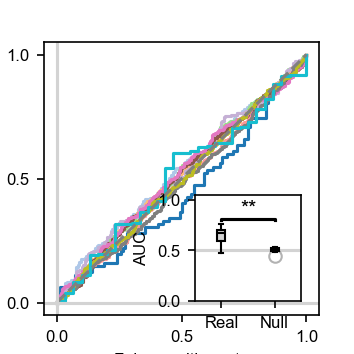

In [61]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, auc
from scipy.stats import mannwhitneyu

# --- Define AUC arrays ---
auc_real = np.array(auc_list)
auc_null = np.array(auc_list_null)
data_to_plot = [auc_real, auc_null]

default()
widget()
arial()

cm_to_inch = 1 / 2.54
fig_width_cm = 6
fig_height_cm = 6

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=150)

# --- Main ROC plot ---
ax_main = fig.add_subplot(1, 1, 1)
for n in range(len(vfish_c_onsets_cont_tot)):
    ax_main.plot(fpr_list_null[n], tpr_list_null[n], '-', color=colors[n], lw=1.5, alpha=1, 
                 label=f'AUC = {auc_null[n]:.2f}' if n == 0 else None)
ax_main.plot([0, 1], [0, 1], color='gray', linestyle='--')

ax_main.set_xlabel('False positive rate')
ax_main.set_ylabel('True positive rate')
ax_main.axhline(0, color='lightgray')
ax_main.axvline(0, color='lightgray')
ax_main.set_xticks([0, 0.5, 1])
ax_main.set_yticks([0, 0.5, 1])
#ax_main.legend(loc="lower right")

# --- Boxplot inset ---
inset_width = 0.3
inset_height = 0.3
inset_x = 0.55   # From left (in figure coordinates)
inset_y = 0.15   # From bottom

ax_inset = fig.add_axes([inset_x, inset_y, inset_width, inset_height])  # [left, bottom, width, height]
ax_inset.axhline(0.5, color='lightgray')
ax_inset.boxplot(data_to_plot, labels=['Real', 'Null'], patch_artist=True,
                 boxprops=dict(facecolor='lightgray', color='black'),
                 medianprops=dict(color='black'),
                 whiskerprops=dict(color='black'),
                 capprops=dict(color='black'),
                 flierprops=dict(marker='o', color='black', alpha=0.3))
ax_inset.set_ylim(0, 1.05)
ax_inset.set_yticks([0, 0.5, 1])
ax_inset.set_ylabel('AUC', fontsize=8)
ax_inset.tick_params(labelsize=8)

# --- Significance test and star ---
stat, p_value = mannwhitneyu(auc_real, auc_null, alternative='greater')
if p_value < 0.001:
    star = '***'
elif p_value < 0.01:
    star = '**'
elif p_value < 0.05:
    star = '*'
else:
    star = 'n.s.'

y_star = max(auc_real.max(), auc_null.max()) + 0.05
x1, x2 = 1, 2
ax_inset.plot([x1, x1, x2, x2], [y_star - 0.01, y_star, y_star, y_star - 0.01], color='black')
ax_inset.text((x1 + x2) / 2, y_star + 0.01, star, ha='center', va='bottom', fontsize=10)

# --- Print AUC summary ---
print('auc_mean', np.mean(auc_real))
print('auc_std', np.std(auc_real))

fig.savefig(os.path.join(path_figures, "Fig_S8a_null_ROC_max_speed_cont_int_all_intermediate_fish.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_S8a_null_ROC_max_speed_cont_int_all_intermediate_fish.pdf"), format="pdf", bbox_inches='tight', dpi=200)
plt.show()

In [62]:
n_shuffles = 1000  # number of random permutations
n_fish = len(vfish_c_onsets_cont_tot)
print(n_fish)
auc_list_null = [[] for _ in range(n_fish)]

for n in range(n_fish):
    x = np.array(Max_vfish_c_onsets_tot_sorted[n])  # continuous scores
    y = np.array(eta_tot_sorted[n])                 # binary labels (0 or 1)

    for _ in range(n_shuffles):
        x_null = np.random.permutation(x)
        y_null = np.random.permutation(y)

        fpr, tpr, _ = roc_curve(y_null, x_null)
        roc_auc = auc(fpr, tpr)

        auc_list_null[n].append(roc_auc)

# Optional: convert to numpy array for easier indexing
auc_list_null = [np.array(auc) for auc in auc_list_null]

11


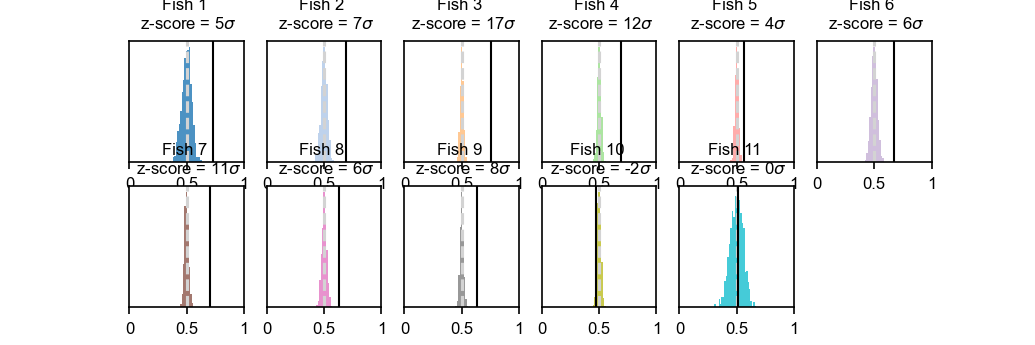

In [78]:
from scipy.stats import norm
import numpy as np
import matplotlib.pyplot as plt

default()
widget()
arial()

n_fish = len(auc_list_null)
n_rows, n_cols = 2, 6  # 4x3 grid

fig, axs = plt.subplots(n_rows, n_cols, figsize=(2.3*3, 2.3), dpi=150)

bins = np.linspace(0, 1, 80)

for idx, ax in enumerate(axs.flat):
    if idx < n_fish:
        null_dist = np.array(auc_list_null[idx])
        real_auc = auc_list[idx]

        # Compute z-score
        mu = np.mean(null_dist)
        sigma = np.std(null_dist, ddof=1)
        z = (real_auc - mu) / sigma if sigma > 0 else np.nan

        ax.hist(null_dist, bins=bins, color=colors[idx], alpha=0.8, density=True, label=f'z-score = {z:.0f}$\sigma$')
        ax.axvline(x=0.5, color='lightgray', linestyle='--')
        ax.axvline(x=real_auc, color='black', linestyle='-', linewidth=1, label='Real AUC')
        ax. set_title(f'Fish {idx+1} \n z-score = {z:.0f}$\sigma$', fontsize=8)
        ax.set_xlim(0, 1)
        ax.set_xticks([0, 0.5, 1], [0, 0.5, 1])
        ax.set_yticks([])
        #ax.legend(frameon=False)
    else:
        ax.axis('off')
plt.savefig(os.path.join(path_figures, "Fig_S8b_STAT_null_ROC_max_speed_cont_int_all_intermediate_fish.pdf"), dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(path_media, "Fig_S8b_STAT_null_ROC_max_speed_cont_int_all_intermediate_fish.pdf"), dpi=200, bbox_inches='tight')
plt.show()

# bout duration - v_max

In [65]:
j = 0
vfish_c_onsets_all_tot[j].shape

(414, 330)

In [66]:

bout_duration_all_tot[j].shape

(414,)

In [67]:
Max_vfish_c_onsets_tot = [[] for _ in range(len(index_i))]
bout_duration__onsets_tot = [[] for _ in range(len(index_i))]
j = 0
for n in range(len(index_i)):

    time_onset = dt * np.arange(-i_before, i_after)
    vfish_c_fish = vfish_c_onsets_all_tot[n]
    bout_duration = bout_duration_all_tot[n]
    
    aux_vmax = []
    aux_bout_dur = []

    for i in range(len(vfish_c_fish)):
        smoothed = gaussian_filter1d(vfish_c_fish[i], sigma=10)
        max_idx = np.argmax(smoothed[:150])
        max_val = smoothed[max_idx]
        max_time = time_onset[max_idx]
        if bout_duration[i]>0.30 and max_val > 0.1:
            aux_vmax.append(max_val)
            aux_bout_dur.append(bout_duration[i])

    Max_vfish_c_onsets_tot[j] = aux_vmax
    bout_duration__onsets_tot[j] = aux_bout_dur
    j = j + 1


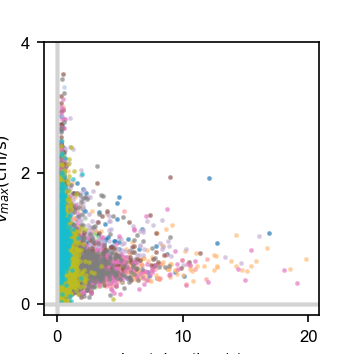

In [69]:
default()
widget()
arial()
cm_to_inch = 1 / 2.54
fig_width_cm = 6
fig_height_cm = 6

fig, ax = plt.subplots(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=150)

for n in range(len(index_i)):
    ax.scatter(bout_duration__onsets_tot[n], Max_vfish_c_onsets_tot[n], color=colors[n],
               s=2, alpha=0.5, rasterized=True)
    ax.axhline(0, color='lightgray')
    ax.axvline(0, color='lightgray')

ax.set_xlabel('bout duration (s)')
ax.set_ylabel(r'$v_{max} (\mathrm{cm/s})$')
ax.set_xticks([0, 10, 20])
ax.set_yticks([0, 20, 40])
ax.set_yticklabels(['0', '2', '4'])


plt.savefig(os.path.join(path_figures, "Fig_S8c_bout_duration_max_speed_rasterized.pdf"), dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(path_media, "Fig_S8c_bout_duration_max_speed_rasterized.pdf"), dpi=200, bbox_inches='tight')
plt.show()

# vtail - onset - one fish

In [70]:
i = 4

In [71]:
vtail_c_onsets_cont = vtail_c_onsets_cont_tot[i] 
vtail_c_onsets_med_cont = np.nanquantile(vtail_c_onsets_cont,0.5,axis=0)
vtail_c_onsets_iqp_cont=np.nanquantile(vtail_c_onsets_cont,0.75,axis=0)-np.nanquantile(vtail_c_onsets_cont,0.5,axis=0)
vtail_c_onsets_iqm_cont=np.nanquantile(vtail_c_onsets_cont,0.5,axis=0)-np.nanquantile(vtail_c_onsets_cont,0.25,axis=0)
vtail_c_onsets_mean_cont = np.nanmean(vtail_c_onsets_cont, axis=0)
vtail_c_onsets_std_cont = np.nanmean(vtail_c_onsets_cont, axis=0)
    
vtail_c_onsets_int = vtail_c_onsets_int_tot[i] 
vtail_c_onsets_med_int = np.nanquantile(vtail_c_onsets_int,0.5,axis=0)
vtail_c_onsets_iqp_int=np.nanquantile(vtail_c_onsets_int,0.75,axis=0)-np.nanquantile(vtail_c_onsets_int,0.5,axis=0)
vtail_c_onsets_iqm_int=np.nanquantile(vtail_c_onsets_int,0.5,axis=0)-np.nanquantile(vtail_c_onsets_int,0.25,axis=0)
vtail_c_onsets_mean_int = np.nanmean(vtail_c_onsets_int, axis=0)
vtail_c_onsets_std_int = np.nanmean(vtail_c_onsets_int, axis=0)

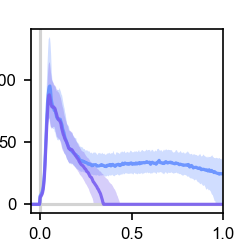

In [72]:
default()
widget()
arial()

cm_to_inch = 1 / 2.54
fig_width_cm = 4.2
fig_height_cm = 4.05

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch),   dpi=150)

plt.axhline(0,color='lightgray')
plt.axvline(0,color='lightgray')


plt.plot(dt*np.arange(-i_before,i_after),vtail_c_onsets_med_cont,c=c_cont,alpha=0.9)
plt.fill_between(dt*np.arange(-i_before,i_after),vtail_c_onsets_med_cont-vtail_c_onsets_iqm_cont,
                 vtail_c_onsets_med_cont+vtail_c_onsets_iqp_cont,color=c_cont,alpha=0.3,ec=None)

plt.plot(dt*np.arange(-i_before,i_after),vtail_c_onsets_med_int,c=c_int,alpha=0.9)
plt.fill_between(dt*np.arange(-i_before,i_after),vtail_c_onsets_med_int-vtail_c_onsets_iqm_int,
                 vtail_c_onsets_med_int+vtail_c_onsets_iqp_int,color=c_int,alpha=0.3,ec=None)

plt.xlim(-0.05,dur_thr)
#plt.ylim(-0.4,17)

plt.xticks([0, 0.5, 1]) #s
plt.xlabel('time (s)')

#plt.yticks([0, 7, 14], ['0.0', '0.7', '1.4']) #cm/s
plt.ylabel(r'$v (\mathrm{cm/s})$')

#plt.legend()

#fig.savefig(os.path.join(path_figures, "example_initial_speedTAIL_cont_int_one_fish.pdf"), format="pdf")

plt.show()

# all fish: one by one

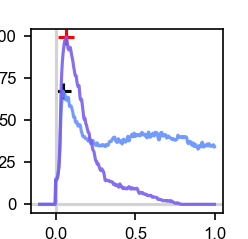

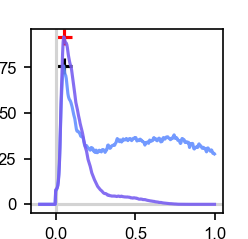

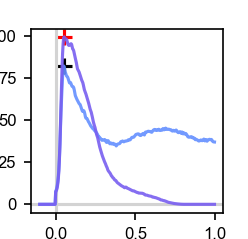

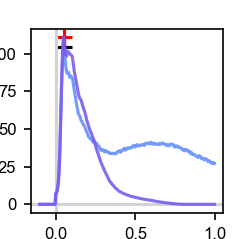

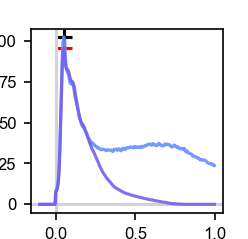

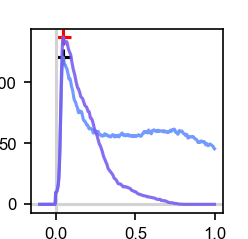

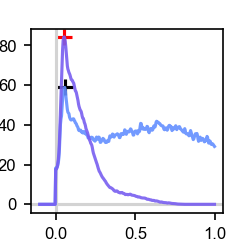

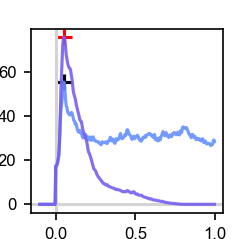

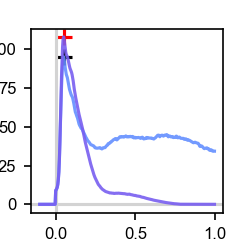

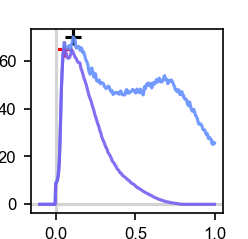

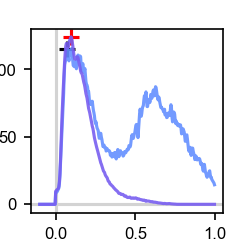

In [73]:
# Dictionary to store all statistics per fish
fish_stats_vtail = {}

for i in range(len(index_i)):
    fish_id = fish_ids[index_i[i]]  # assuming you have a list of fish_ids

    fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=150)
    time_onset = dt * np.arange(-i_before, i_after)

    # CONTINUOUS
    vtail_c_onsets_cont = vtail_c_onsets_cont_tot[i]
    med_cont = np.nanquantile(vtail_c_onsets_cont, 0.5, axis=0)
    iqp_cont = np.nanquantile(vtail_c_onsets_cont, 0.75, axis=0) - med_cont
    iqm_cont = med_cont - np.nanquantile(vtail_c_onsets_cont, 0.25, axis=0)
    mean_cont = np.nanmean(vtail_c_onsets_cont, axis=0)
    std_cont = np.nanstd(vtail_c_onsets_cont, axis=0)

    # INTERMITTENT
    vtail_c_onsets_int = vtail_c_onsets_int_tot[i]
    med_int = np.nanquantile(vtail_c_onsets_int, 0.5, axis=0)
    iqp_int = np.nanquantile(vtail_c_onsets_int, 0.75, axis=0) - med_int
    iqm_int = med_int - np.nanquantile(vtail_c_onsets_int, 0.25, axis=0)
    mean_int = np.nanmean(vtail_c_onsets_int, axis=0)
    std_int = np.nanstd(vtail_c_onsets_int, axis=0)

    # Max values
    vmax_cont = np.nanmax(mean_cont)
    tmax_cont = time_onset[np.nanargmax(mean_cont)]

    vmax_int = np.nanmax(mean_int)
    tmax_int = time_onset[np.nanargmax(mean_int)]

    # Plotting
    plt.axhline(0, color='lightgray')
    plt.axvline(0, color='lightgray')
    plt.plot(time_onset, mean_cont, c=c_cont, alpha=0.9)
    plt.plot(time_onset, mean_int, c=c_int, alpha=0.9)
    plt.scatter(tmax_cont, vmax_cont, color='black', marker='+', s=60)
    plt.scatter(tmax_int, vmax_int, color='red', marker='+', s=60)

    # Store statistics
    fish_stats_vtail[fish_id] = {
        'cont': {
            'time_onset': time_onset,
            'mean': mean_cont,
            'std': std_cont,
            'median': med_cont,
            'iqr_minus': iqm_cont,
            'iqr_plus': iqp_cont,
            'vmax': vmax_cont,
            'tmax': tmax_cont
        },
        'int': {
            'time_onset': time_onset,
            'mean': mean_int,
            'std': std_int,
            'median': med_int,
            'iqr_minus': iqm_int,
            'iqr_plus': iqp_int,
            'vmax': vmax_int,
            'tmax': tmax_int
        }
    }

In [74]:
import pickle

with open(os.path.join(path_data, "vtail_intermidiate_fishbyfish_stats.pkl"), "wb") as f:
    pickle.dump(fish_stats_vtail, f)

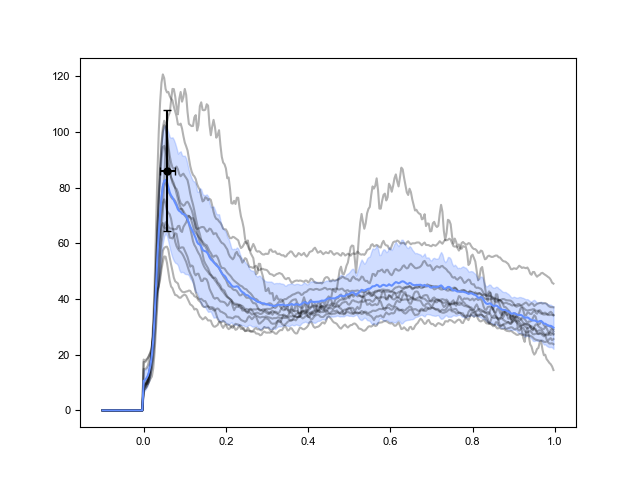

In [75]:
# Stack all 'cont' mean traces into an array
cont_means = np.stack([fish_stats_vtail[fish_ids[index_i[i]]]['cont']['mean'] for i in range(len(index_i))])
cont_vmaxs = np.stack([fish_stats_vtail[fish_ids[index_i[i]]]['cont']['vmax'] for i in range(len(index_i))])
cont_tmaxs = np.stack([fish_stats_vtail[fish_ids[index_i[i]]]['cont']['tmax'] for i in range(len(index_i))])

cont_mean_across_fish = np.nanmean(cont_means, axis=0)
cont_std_across_fish = np.nanstd(cont_means, axis=0)

cont_mean_vmax_across_fish = np.nanmean(cont_vmaxs, axis=0)
cont_std_vmax_across_fish = np.nanstd(cont_vmaxs, axis=0)

cont_mean_tmax_across_fish = np.nanmean(cont_tmaxs, axis=0)
cont_std_tmax_across_fish = np.nanstd(cont_tmaxs, axis=0)

plt.figure()
for i in range(len(index_i)):
    time_onset = dt * np.arange(-i_before, i_after)
    plt.plot(time_onset, fish_stats_vtail[fish_ids[index_i[i]]]['cont']['mean'], 'black', alpha = 0.3)
plt.plot(time_onset, cont_mean_across_fish, color=c_cont)
plt.fill_between(time_onset,cont_mean_across_fish-cont_std_across_fish,cont_mean_across_fish+cont_std_across_fish,color=c_cont,alpha=0.3)
plt.errorbar(cont_mean_tmax_across_fish, cont_mean_vmax_across_fish, 
             xerr=cont_std_tmax_across_fish, yerr=cont_std_vmax_across_fish, 
             fmt='o', color='black', markersize=5, capsize=3)
plt.show()

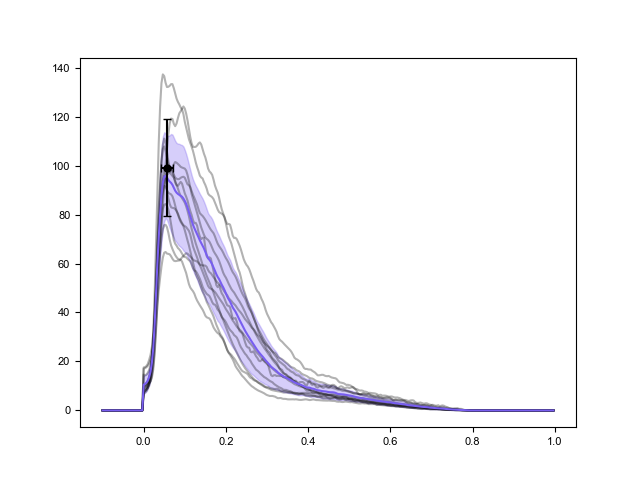

In [76]:
# Stack all 'int' mean traces into an array
int_means = np.stack([fish_stats_vtail[fish_ids[index_i[i]]]['int']['mean'] for i in range(len(index_i))])
int_vmaxs = np.stack([fish_stats_vtail[fish_ids[index_i[i]]]['int']['vmax'] for i in range(len(index_i))])
int_tmaxs = np.stack([fish_stats_vtail[fish_ids[index_i[i]]]['int']['tmax'] for i in range(len(index_i))])

# Compute mean and std across fish
int_mean_across_fish = np.nanmean(int_means, axis=0)
int_std_across_fish = np.nanstd(int_means, axis=0)

int_mean_vmax_across_fish = np.nanmean(int_vmaxs, axis=0)
int_std_vmax_across_fish = np.nanstd(int_vmaxs, axis=0)

int_mean_tmax_across_fish = np.nanmean(int_tmaxs, axis=0)
int_std_tmax_across_fish = np.nanstd(int_tmaxs, axis=0)

# Plotting
plt.figure()
for i in range(len(index_i)):
    time_onset = dt * np.arange(-i_before, i_after)
    plt.plot(time_onset, fish_stats_vtail[fish_ids[index_i[i]]]['int']['mean'], 'black', alpha=0.3)
plt.plot(time_onset, int_mean_across_fish, color=c_int)
plt.fill_between(time_onset, int_mean_across_fish - int_std_across_fish,
                 int_mean_across_fish + int_std_across_fish, color=c_int, alpha=0.3)
plt.errorbar(int_mean_tmax_across_fish, int_mean_vmax_across_fish,
             xerr=int_std_tmax_across_fish, yerr=int_std_vmax_across_fish,
             fmt='o', color='black', markersize=5, capsize=3)
plt.show()

0.05727272727272728 86.11787235075518
0.056666666666666664 99.23472669378611


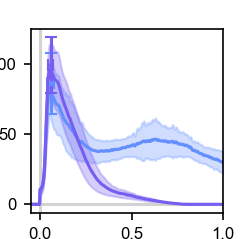

In [77]:
default()
widget()
arial()

cm_to_inch = 1 / 2.54
fig_width_cm = 4.2
fig_height_cm = 4.05

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch),   dpi=150)

plt.axhline(0,color='lightgray')
plt.axvline(0,color='lightgray')

plt.plot(time_onset, cont_mean_across_fish, color=c_cont)
plt.fill_between(time_onset,cont_mean_across_fish-cont_std_across_fish,
                 cont_mean_across_fish+cont_std_across_fish,color=c_cont,alpha=0.3)
plt.errorbar(cont_mean_tmax_across_fish, cont_mean_vmax_across_fish, 
             xerr=cont_std_tmax_across_fish, yerr=cont_std_vmax_across_fish, 
             fmt='.', color=c_cont, markersize=3, capsize=3)

plt.plot(time_onset, int_mean_across_fish, color=c_int)
plt.fill_between(time_onset, int_mean_across_fish - int_std_across_fish,
                 int_mean_across_fish + int_std_across_fish, color=c_int, alpha=0.3)
plt.errorbar(int_mean_tmax_across_fish, int_mean_vmax_across_fish,
             xerr=int_std_tmax_across_fish, yerr=int_std_vmax_across_fish,
             fmt='.', color=c_int, markersize=3, capsize=3)

plt.xlim(-0.05,dur_thr)
#plt.ylim(-0.4,10)

plt.xticks([0, 0.5, 1]) #s
plt.xlabel('time (s)')

#plt.yticks([0, 5, 10], ['0.0', '0.5', '1.0']) #cm/s
plt.ylabel(r'$v_{f} (\mathrm{cm/s})$')


#fig.savefig(os.path.join(path_figures, "initial_speedTAIL_cont_int_all_fish.pdf"), format="pdf")
#fig.savefig(os.path.join(path_media, "initial_speedTAIL_cont_int_all_fish.pdf"), format="pdf", bbox_inches='tight', dpi=200)

print(cont_mean_tmax_across_fish, cont_mean_vmax_across_fish)
print(int_mean_tmax_across_fish, int_mean_vmax_across_fish)
plt.show()